# 1. Before context engineering

Compare XGBoost and SAP RPT on the original 128 held-out synthetic invoices, including 22 fraud cases. The first 1,024 rows supplied training data to XGBoost and labeled examples to SAP RPT. This notebook verifies saved IDs, labels, and BTP result hashes, then recomputes classification metrics. It makes no live SAP request.

XGBoost uses fraud class weighting and a 0.5 decision threshold; RPT returns top-1 classes. The saved RPT response does not supply a positive-class score for every invoice, so its ROC AUC and average precision are unavailable. The separate eight-case pilot uses different fraud labels and is excluded.

## 1. Validate the dataset and XGBoost predictions

In [1]:
import hashlib
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score, average_precision_score, roc_curve, precision_recall_curve, confusion_matrix

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "data/synthetic_invoices/payment_behavior.csv").exists())
DATA = ROOT / "data/synthetic_invoices"
TARGETS = ("paid_late", "is_fraud")
CONTEXT_ROWS = 1024
PREDICTION_ROWS = 128
source = pd.read_csv(ROOT / 'archive/synthetic_invoice_experiments/published_baseline' / "payment_behavior.csv")
test = source.iloc[CONTEXT_ROWS:].reset_index(drop=True)
xgb = pd.read_csv(DATA / "xgboost_results.csv")
assert len(source) == 1152 and len(test) == len(xgb) == PREDICTION_ROWS
assert source.invoice_id.is_unique and xgb.invoice_id.is_unique
assert int(source.is_fraud.iloc[:CONTEXT_ROWS].sum()) == 187
assert int(test.is_fraud.sum()) == 22 and int(test.paid_late.sum()) == 51
assert xgb.invoice_id.tolist() == test.invoice_id.tolist()
for target in TARGETS:
    assert xgb[f"actual_{target}"].tolist() == test[target].tolist()
    assert xgb[f"predicted_{target}"].isin([0, 1]).all()
    assert xgb[f"probability_{target}"].between(0, 1).all()
print(f"Validated XGBoost on {len(test)} test invoices: {int(test.paid_late.sum())} paid late, {int(test.is_fraud.sum())} fraud.")

Validated XGBoost on 128 test invoices: 51 paid late, 22 fraud.


## 2. Validate the saved direct BTP result

The public metadata records model name, run time, and hashes of the RPT request and scored results. The raw BTP response and local credentials are excluded from the published repository.

In [2]:
btp_path = DATA / "rpt16_results.csv"
metadata_path = DATA / "rpt16_run_metadata.json"
request_path = DATA / "rpt16_request.json"
if not btp_path.exists() or not metadata_path.exists():
    raise FileNotFoundError("Saved BTP results are missing. Configure SAP BTP and run scripts/run_rpt16_invoices.py to create them.")
metadata = json.loads(metadata_path.read_text(encoding="utf-8"))
assert metadata["source"] == "btp_deployment"
assert metadata["request_sha256"] == hashlib.sha256(request_path.read_bytes()).hexdigest()
assert metadata["results_sha256"] == hashlib.sha256(btp_path.read_bytes()).hexdigest()
assert metadata["test_rows"] == PREDICTION_ROWS
rpt = pd.read_csv(btp_path)
assert len(rpt) == PREDICTION_ROWS and rpt.invoice_id.is_unique
assert rpt.invoice_id.tolist() == test.invoice_id.tolist()
for target in TARGETS:
    assert rpt[f"actual_{target}"].tolist() == test[target].tolist()
    assert rpt[f"predicted_{target}"].isin([0, 1]).all()
    assert rpt[f"confidence_{target}"].between(0, 1).all()
print(f"Validated direct {metadata['model_configured']} BTP result from {metadata['run_at_utc']} (UTC).")

Validated direct sap-rpt-1.6-large BTP result from 2026-10-03T22:17:05.746027+00:00 (UTC).


## 3. Calculate comparable metrics

Accuracy, precision, and recall use predicted class labels. XGBoost ROC AUC and average precision use its saved class-1 probabilities. Average precision summarizes the precision–recall curve and is especially useful for fraud, where 22 of 128 invoices are positive. RPT ranking metrics are unavailable from this top-1 response. For fraud, show true positives and false alarms alongside percentages.

In [3]:
metric_rows = []
confusion_rows = []
for model_name, frame in [("XGBoost", xgb), ("SAP RPT 1.6 BTP", rpt)]:
    for target in TARGETS:
        actual = frame[f"actual_{target}"]
        predicted = frame[f"predicted_{target}"]
        tn, fp, fn, tp = confusion_matrix(actual, predicted, labels=[0, 1]).ravel()
        metric_rows.append({
            "Model": model_name, "Target": target, "Positive cases": int(actual.sum()),
            "Accuracy": accuracy_score(actual, predicted),
            "Precision": precision_score(actual, predicted, zero_division=0),
            "Recall": recall_score(actual, predicted, zero_division=0),
            "ROC AUC": roc_auc_score(actual, frame[f"probability_{target}"]) if model_name == "XGBoost" else float("nan"),
            "Average precision": average_precision_score(actual, frame[f"probability_{target}"]) if model_name == "XGBoost" else float("nan"),
        })
        confusion_rows.append({"Model": model_name, "Target": target,
                               "True positives": int(tp), "False positives": int(fp),
                               "False negatives": int(fn), "True negatives": int(tn)})
metrics = pd.DataFrame(metric_rows).set_index(["Model", "Target"])
confusion = pd.DataFrame(confusion_rows).set_index(["Model", "Target"])
display(metrics.round(3))
display(confusion)

Positive cases  Accuracy  ...  ROC AUC  Average precision
Model           Target                               ...                            
XGBoost         paid_late              51     0.656  ...    0.724              0.640
                is_fraud               22     0.875  ...    0.804              0.587
SAP RPT 1.6 BTP paid_late              51     0.711  ...      NaN                NaN
                is_fraud               22     0.867  ...      NaN                NaN

[4 rows x 6 columns]

True positives  ...  True negatives
Model           Target                     ...                
XGBoost         paid_late              32  ...              52
                is_fraud               15  ...              97
SAP RPT 1.6 BTP paid_late              34  ...              57
                is_fraud               10  ...             101

[4 rows x 4 columns]

## 4. Visualize the trade-off

The left panel compares late-payment metrics. The right panel shows how many of the 22 fraud cases each model found and how many non-fraud invoices it flagged by mistake.

Saved notebooks/saved_results_comparison.png


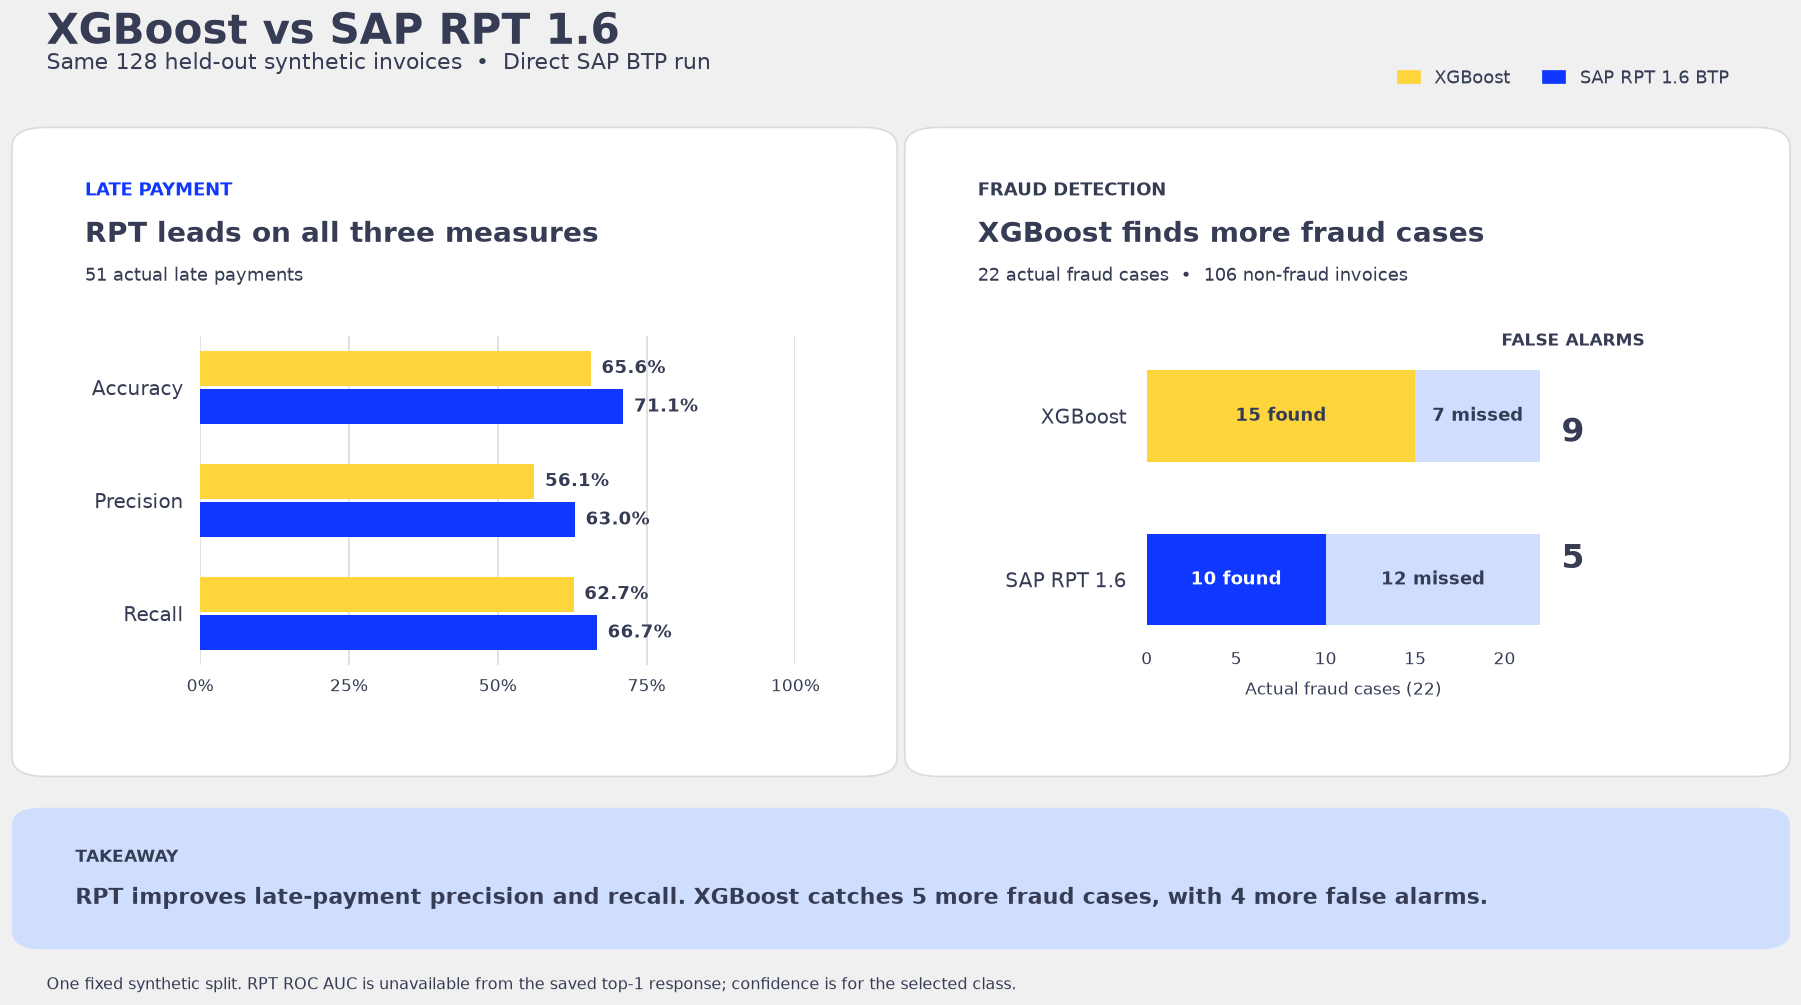

In [4]:
from matplotlib.patches import FancyBboxPatch, Patch

COLORS = {"XGBoost": "#FFD53C", "SAP RPT 1.6 BTP": "#0F37FF"}
INK = "#353C54"
MUTED = "#353C54"
PANEL = "#FFFFFF"
BACKGROUND = "#F0F0F0"
MISSED = "#CFDEFF"

fig = plt.figure(figsize=(16, 9), facecolor=BACKGROUND)
fig.text(.055, .935, "XGBoost vs SAP RPT 1.6", fontsize=25, color=INK, weight="bold", va="top")
fig.text(.055, .882, "Same 128 held-out synthetic invoices  •  Direct SAP BTP run", fontsize=13, color=MUTED)
fig.legend(handles=[Patch(color=COLORS[name], label=name) for name in COLORS],
           loc="upper right", bbox_to_anchor=(.94, .897), ncol=2, frameon=False,
           fontsize=11, labelcolor=INK, handlelength=1.2, columnspacing=1.8)

for x, width in ((.045, .445), (.510, .445)):
    fig.add_artist(FancyBboxPatch((x, .235), width, .585,
                   boxstyle="round,pad=0.008,rounding_size=0.018",
                   # Figure-level cards need a negative z-order; otherwise they cover the plotted bars.
                   transform=fig.transFigure, facecolor=PANEL, edgecolor="#DBDBDB", linewidth=1, zorder=-10))

fig.text(.075, .765, "LATE PAYMENT", color=COLORS["SAP RPT 1.6 BTP"], fontsize=11, weight="bold")
fig.text(.075, .722, "RPT leads on all three measures", color=INK, fontsize=17, weight="bold")
fig.text(.075, .686, "51 actual late payments", color=MUTED, fontsize=11)

late_ax = fig.add_axes([.135, .330, .310, .305], facecolor="none")
metric_labels = ["Accuracy", "Precision", "Recall"]
for offset, name in ((.17, "XGBoost"), (-.17, "SAP RPT 1.6 BTP")):
    values = [metrics.loc[(name, "paid_late"), measure] for measure in metric_labels]
    bars = late_ax.barh([2 + offset, 1 + offset, 0 + offset], values,
                        height=.31, color=COLORS[name], zorder=3)
    for bar, value in zip(bars, values):
        late_ax.text(value + .018, bar.get_y() + bar.get_height()/2, f"{value:.1%}",
                     va="center", fontsize=11, color=INK, weight="bold")
late_ax.set_yticks([2, 1, 0], metric_labels, color=INK, fontsize=12)
late_ax.set_xlim(0, 1)
late_ax.set_xticks([0, .25, .5, .75, 1], ["0%", "25%", "50%", "75%", "100%"])
late_ax.tick_params(axis="x", colors=MUTED, labelsize=10, length=0, pad=8)
late_ax.tick_params(axis="y", length=0, pad=10)
late_ax.xaxis.grid(True, color="#DBDBDB", linewidth=1)
late_ax.set_axisbelow(True)
for spine in late_ax.spines.values(): spine.set_visible(False)

fig.text(.540, .765, "FRAUD DETECTION", color=INK, fontsize=11, weight="bold")
fig.text(.540, .722, "XGBoost finds more fraud cases", color=INK, fontsize=17, weight="bold")
fig.text(.540, .686, "22 actual fraud cases  •  106 non-fraud invoices", color=MUTED, fontsize=11)
fig.text(.850, .626, "FALSE ALARMS", color=MUTED, fontsize=10, weight="bold", ha="center")

fraud_ax = fig.add_axes([.628, .355, .205, .260], facecolor="none")
for row, name in ((1, "XGBoost"), (0, "SAP RPT 1.6 BTP")):
    counts = confusion.loc[(name, "is_fraud")]
    found = int(counts["True positives"])
    missed = int(counts["False negatives"])
    false_alarms = int(counts["False positives"])
    fraud_ax.barh(row, found, height=.56, color=COLORS[name], zorder=3)
    fraud_ax.barh(row, missed, left=found, height=.56, color=MISSED, zorder=3)
    fraud_ax.text(found/2, row, f"{found} found", ha="center", va="center",
                  color=INK if name == "XGBoost" else "white", fontsize=11, weight="bold")
    fraud_ax.text(found + missed/2, row, f"{missed} missed", ha="center", va="center",
                  color=INK, fontsize=11, weight="bold")
    fig.text(.850, .545 if row == 1 else .428, str(false_alarms),
             color=INK, fontsize=20, weight="bold", ha="center", va="center")
fraud_ax.set_yticks([1, 0], ["XGBoost", "SAP RPT 1.6"], fontsize=12, color=INK)
fraud_ax.set_xlim(0, 22)
fraud_ax.set_xticks([0, 5, 10, 15, 20])
fraud_ax.tick_params(axis="x", colors=MUTED, labelsize=10, length=0, pad=8)
fraud_ax.tick_params(axis="y", length=0, pad=12)
fraud_ax.set_xlabel("Actual fraud cases (22)", color=MUTED, fontsize=10, labelpad=8)
for spine in fraud_ax.spines.values(): spine.set_visible(False)

fig.add_artist(FancyBboxPatch((.045, .075), .910, .115,
               boxstyle="round,pad=0.008,rounding_size=0.016",
               transform=fig.transFigure, facecolor="#CFDEFF", edgecolor="none", zorder=-10))
fig.text(.070, .148, "TAKEAWAY", fontsize=10, color=MUTED, weight="bold")
fig.text(.070, .109,
         "RPT improves late-payment precision and recall. XGBoost catches 5 more fraud cases, with 4 more false alarms.",
         fontsize=13, color=INK, weight="bold")
fig.text(.055, .030,
         "One fixed synthetic split. RPT ROC AUC is unavailable from the saved top-1 response; confidence is for the selected class.",
         fontsize=9.5, color=MUTED)

chart_path = ROOT / "notebooks/saved_results_comparison.png"
fig.savefig(chart_path, dpi=250, facecolor=BACKGROUND)
plt.show()
print(f"Saved {chart_path.relative_to(ROOT)}")

## 5. ROC and precision–recall curves

The curves use XGBoost's positive-class probability on the **same fixed holdout**. ROC AUC summarizes ranking across thresholds; average precision summarizes the precision–recall curve. The dashed precision baseline is the positive fraction in this holdout. These curves do not describe performance at the chosen 0.5 threshold; use the confusion counts above for that decision. SAP RPT is omitted because its saved top-1 confidence is not a positive-class score for every invoice. Do not treat `1 − confidence` as a verified class score.

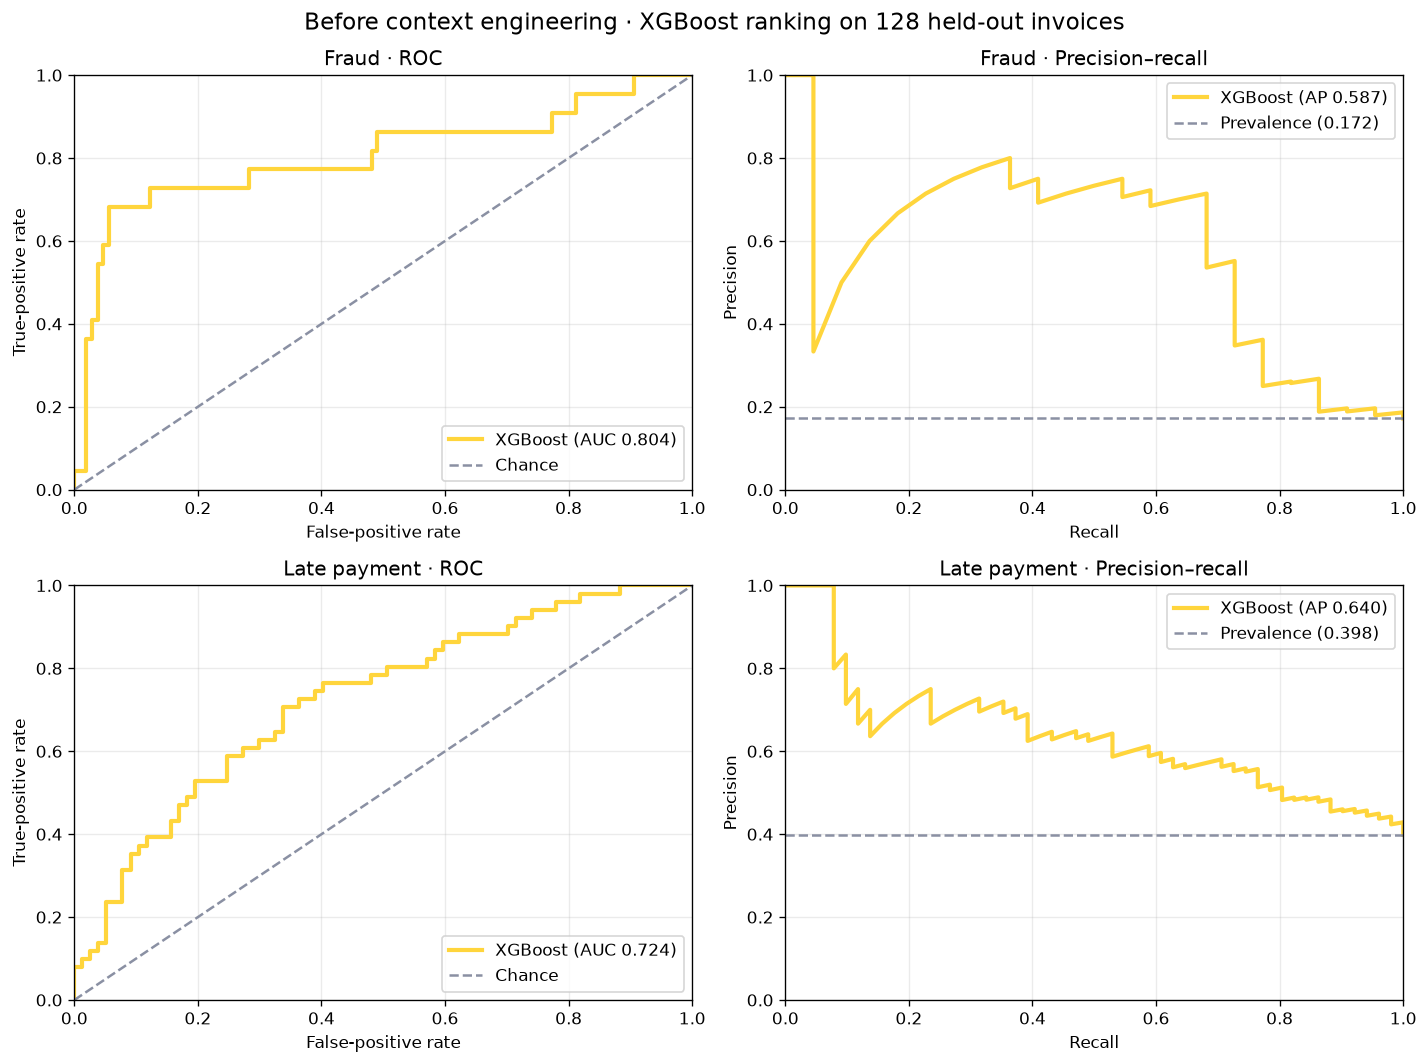

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for row, (target, label) in enumerate((("is_fraud", "Fraud"), ("paid_late", "Late payment"))):
    actual = xgb[f"actual_{target}"].to_numpy()
    score = xgb[f"probability_{target}"].to_numpy()
    false_positive_rate, true_positive_rate, _ = roc_curve(actual, score)
    precision, recall, _ = precision_recall_curve(actual, score)
    roc_auc = roc_auc_score(actual, score)
    average_precision = average_precision_score(actual, score)

    roc_ax, pr_ax = axes[row]
    roc_ax.plot(false_positive_rate, true_positive_rate, color="#FFD53C", linewidth=2.5,
                label=f"XGBoost (AUC {roc_auc:.3f})")
    roc_ax.plot([0, 1], [0, 1], linestyle="--", color="#8A90A3", label="Chance")
    roc_ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="False-positive rate",
               ylabel="True-positive rate", title=f"{label} · ROC")
    roc_ax.legend(loc="lower right")

    pr_ax.plot(recall, precision, color="#FFD53C", linewidth=2.5,
               label=f"XGBoost (AP {average_precision:.3f})")
    pr_ax.axhline(actual.mean(), linestyle="--", color="#8A90A3",
                  label=f"Prevalence ({actual.mean():.3f})")
    pr_ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Recall", ylabel="Precision",
              title=f"{label} · Precision–recall")
    pr_ax.legend(loc="upper right")
    for ax in (roc_ax, pr_ax):
        ax.grid(alpha=.25)
fig.suptitle("Before context engineering · XGBoost ranking on 128 held-out invoices", fontsize=14)
fig.tight_layout()
plt.show()

## Takeaways

On this 128-invoice synthetic test set, SAP RPT 1.6 has higher late-payment accuracy (71.1% versus 65.6%) and recall (66.7% versus 62.7%). For fraud, XGBoost finds 15 of 22 cases with 9 false alarms; RPT finds 10 of 22 with 5 false alarms. XGBoost has higher fraud recall, while RPT has fewer false alarms and slightly higher fraud precision. XGBoost fraud ROC AUC is **0.804** and average precision is **0.587**; late-payment ROC AUC is **0.724** and average precision is **0.640**. The saved BTP top-1 response does not support comparable RPT ranking metrics. This fixed synthetic split does not establish production performance.